In [1]:
# Setup
import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

DATA_FILE = "tep_sp_run.h5"
T_RANGE = (100, 200)

In [2]:
# Load data
def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


data, names = {}, {}
with h5py.File(DATA_FILE, "r") as f:
    t = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "sp", "dist", "y"]:
        if key in f:
            data[key] = f[key][()]
            names[key] = read_names(f[key])
    shutdown = bool(f.attrs.get("shutdown", False))
    config = json.loads(f.attrs["config"]) if "config" in f.attrs else {}

nominal = {int(k): v for k, v in config["setpoints"].items()}
schedule = sorted(config.get("setpoint_schedule", []), key=lambda e: e[1])
changed = sorted({k for k, _, _ in schedule})   # set points that are changed in this run
t_test = config.get("t_test")                   # start of the test changes (h)

# Samples where a changed set point is off its nominal value
off_nominal = np.zeros(len(t), dtype=bool)
for k in changed:
    off_nominal |= np.abs(data["sp"][:, k - 1] - nominal[k]) > 1e-9

def time_mask():
    t_range = T_RANGE
    if t_range is None:
        return np.ones(len(t), dtype=bool)
    mask = (t >= t_range[0]) & (t <= t_range[1])
    if mask.sum() < 2:
        raise ValueError(f"t_range {t_range} h has no data, file covers {t[0]:.2f} - {t[-1]:.2f} h")
    return mask

print(f"{DATA_FILE}: {len(t)} samples, {t[0]:.2f} - {t[-1]:.2f} h, every {(t[1] - t[0]) * 60:.0f} min"
      + (", plant shut down" if shutdown else ""))
print(f"noise: {config.get('noise')}, seed: {config.get('seed')}, test part from: {t_test} h")
print(f"AR(1) std: {config.get('dist_std')}")
print(f"AR(1) tau (h): {config.get('dist_tau')}")
print("datasets: " + ", ".join(f"{k} {v.shape}" for k, v in data.items()))

tep_sp_run.h5: 6998 samples, 0.05 - 349.90 h, every 3 min
noise: False, seed: 0, test part from: 297.8 h
AR(1) std: [0.001, 0.00015, 1.0, 1.0, 0.5, 0.2, 0.005, 0.005, 0.02, 0.01, 0.01, 0.01]
AR(1) tau (h): [6.0, 6.0, 6.0, 6.0, 3.0, 3.0, 10.0, 10.0, 6.0, 3.0, 3.0, 3.0]
datasets: xmeas (6998, 41), xmv (6998, 12), sp (6998, 20), dist (6998, 12), y (6998, 50)


In [3]:
# Set point change events (excursions from nominal)
end_t = config.get("hours", t[-1])
events = []
for k in changed:
    entries = [e for e in schedule if e[0] == k]
    for (_, t_on, v), nxt in zip(entries, entries[1:] + [None]):
        if abs(v - nominal[k]) > 1e-9:
            t_off = nxt[1] if nxt else end_t
            events.append((t_on, t_off, k, v))
events.sort()

event_table = pd.DataFrame(
    [
        {
            "part": "test" if t_test is not None and t_on >= t_test else "train",
            "SETPT": k,
            "description": names["sp"][k - 1],
            "nominal": nominal[k],
            "new value": v,
            "change": round(v - nominal[k], 6),
            "change (%)": round(100 * (v - nominal[k]) / nominal[k], 2),
            "start (h)": t_on,
            "end (h)": t_off,
            "duration (h)": round(t_off - t_on, 2),
        }
        for t_on, t_off, k, v in events
    ]
)
event_table.index.name = "EVENT_INDEX"
print(f"{(event_table['part'] == 'test').sum()} test excursions from {t_test} h")
print(f"{len(events)} set point excursions on {len(changed)} set points, "
      f"{(~off_nominal).mean():.0%} of samples at nominal set points")
pd.set_option("display.max_rows", 200)
event_table

11 test excursions from 297.8 h
77 set point excursions on 11 set points, 56% of samples at nominal set points


,part,SETPT,description,nominal,new value,change,change (%),start (h),end (h),duration (h)
EVENT_INDEX,,,,,,,,,,
0,train,14,Reactor feed D (mol%),6.8820,7.2820,0.400,5.81,10.00,12.50,2.5
1,train,18,Reactor temperature (C),120.4000,121.4500,1.050,0.87,15.10,16.10,1.0
2,train,19,Purge B (mol%),13.8230,12.4230,-1.400,-10.13,17.40,19.90,2.5
3,train,17,Reactor level (%),75.0000,75.8750,0.875,1.17,22.80,24.80,2.0
4,train,8,Stripper level (%),50.0000,55.6000,5.600,11.20,26.90,27.90,1.0
5,train,13,Reactor feed A (mol%),32.1880,33.3880,1.200,3.73,29.05,31.55,2.5
6,train,11,Stripper underflow (m3/h),22.9490,23.2290,0.280,1.22,34.50,36.50,2.0
7,train,17,Reactor level (%),75.0000,73.2500,-1.750,-2.33,38.80,40.80,2.0
8,train,14,Reactor feed D (mol%),6.8820,6.6020,-0.280,-4.07,43.05,45.55,2.5


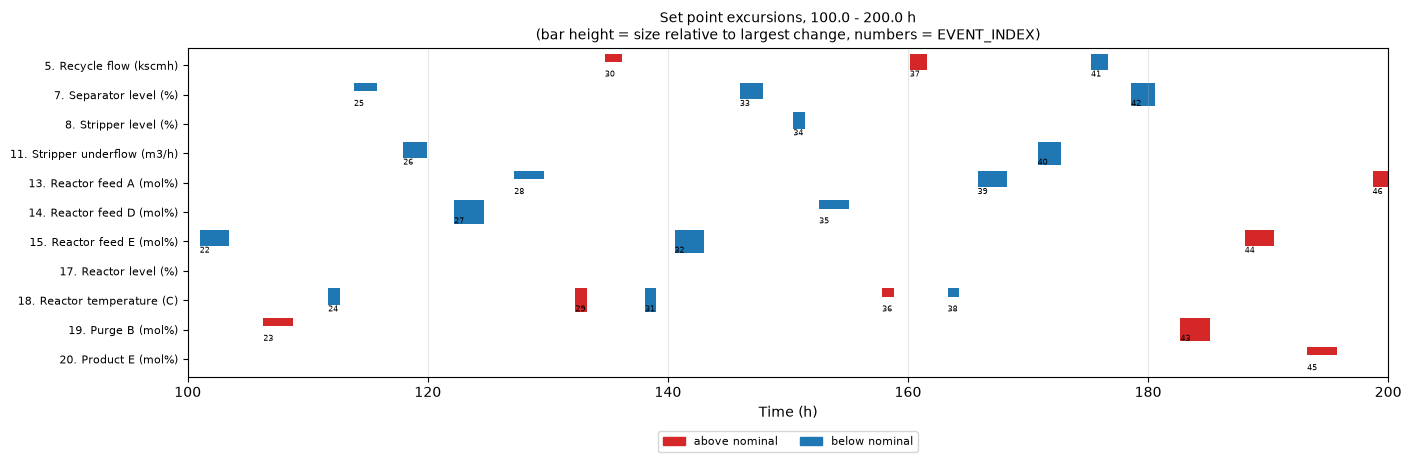

In [4]:
# Set point change timeline
shown = time_mask()
fig, ax = plt.subplots(figsize=(14, 4.5), layout="constrained")
for row, k in enumerate(changed):
    dev = (data["sp"][:, k - 1] - nominal[k])
    dmax = np.abs(dev).max()
    ax.fill_between(t[shown], row, row + 0.8 * np.abs(dev[shown]) / dmax, where=dev[shown] > 0,
                    step="post", color="tab:red", lw=0)
    ax.fill_between(t[shown], row, row + 0.8 * np.abs(dev[shown]) / dmax, where=dev[shown] < 0,
                    step="post", color="tab:blue", lw=0)
for k_ev, (t_on, _, k, _) in enumerate(events):
    if shown[np.searchsorted(t, t_on).clip(max=len(t) - 1)]:
        ax.text(t_on, changed.index(k) + 0.85, str(k_ev), fontsize=6, ha="left", va="bottom")
if t_test is not None and shown[np.searchsorted(t, t_test).clip(max=len(t) - 1)]:
    ax.axvline(t_test, color="k", ls="--", lw=1, label="test part")
ax.fill_between([], [], color="tab:red", label="above nominal")
ax.fill_between([], [], color="tab:blue", label="below nominal")
ax.set_yticks([r + 0.4 for r in range(len(changed))])
ax.set_yticklabels([f"{k}. {names['sp'][k - 1]}" for k in changed], fontsize=8)
ax.set_ylim(-0.2, len(changed))
ax.invert_yaxis()
ax.set_xlim(t[shown][0], t[shown][-1])
ax.set_xlabel("Time (h)")
ax.set_title(f"Set point excursions, {t[shown][0]:.1f} - {t[shown][-1]:.1f} h\n"
             "(bar height = size relative to largest change, numbers = EVENT_INDEX)", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8, ncols=3)
ax.grid(alpha=0.3, axis="x")
plt.show()

In [5]:
# Plotting
def grid(values, labels, title, ncols, idx=None):
    shown = time_mask()
    idx = list(range(values.shape[1])) if idx is None else idx
    n = len(idx)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows + 0.6), sharex=True,
                             squeeze=False, layout="constrained")
    for j, ax in enumerate(axes.ravel()):
        if j >= n:
            ax.axis("off")
            continue
        i = idx[j]
        ax.fill_between(t[shown], 0, 1, where=off_nominal[shown], color="tab:red", alpha=0.1,
                        transform=ax.get_xaxis_transform(), step="post", lw=0)
        if t_test is not None and shown[np.searchsorted(t, t_test).clip(max=len(t) - 1)]:
            ax.axvline(t_test, color="k", ls="--", lw=0.8)
        ax.plot(t[shown], values[shown, i], lw=0.6)
        ax.set_xlim(t[shown][0], t[shown][-1])
        ax.set_title(f"{i + 1}. {labels[i]}", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Time (h)", fontsize=8)
    fig.suptitle(f"{title} - {DATA_FILE}, {t[shown][0]:.1f} - {t[shown][-1]:.1f} h\n"
                 "red shading: set point off nominal, dashed line: start of test part", fontsize=11)
    plt.show()

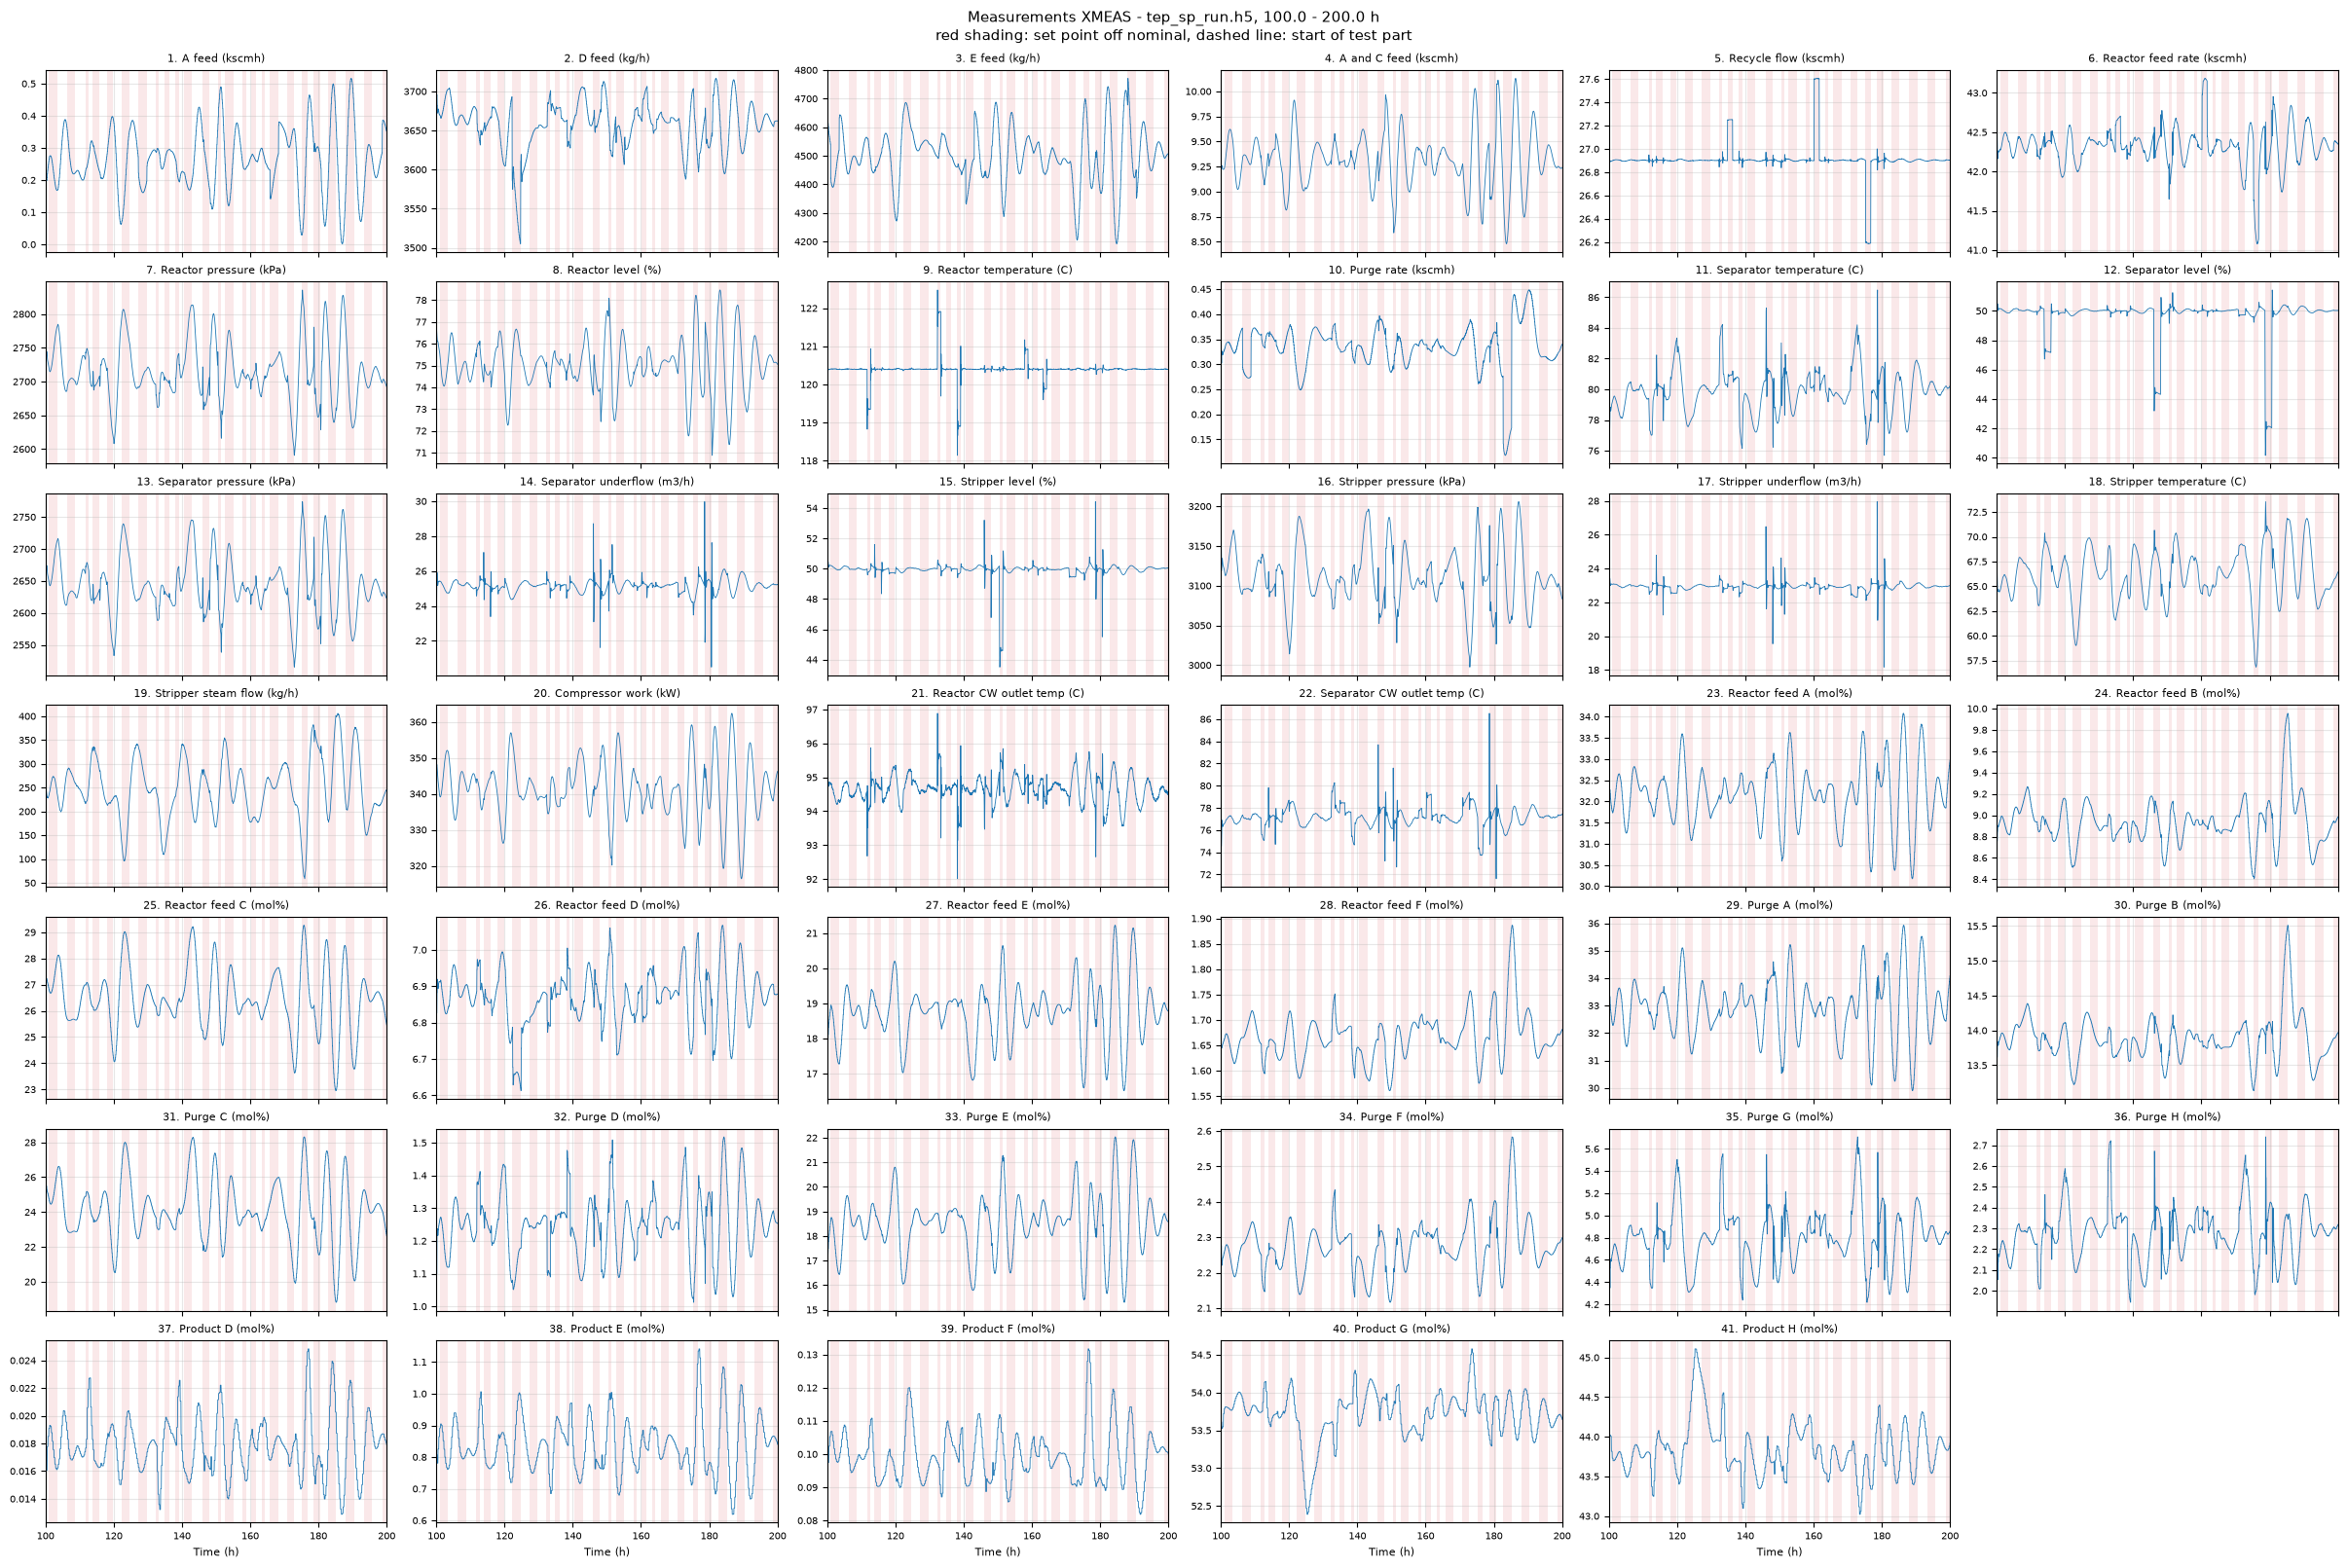

In [6]:
# Measurements XMEAS
grid(data["xmeas"], names["xmeas"], "Measurements XMEAS", 6)

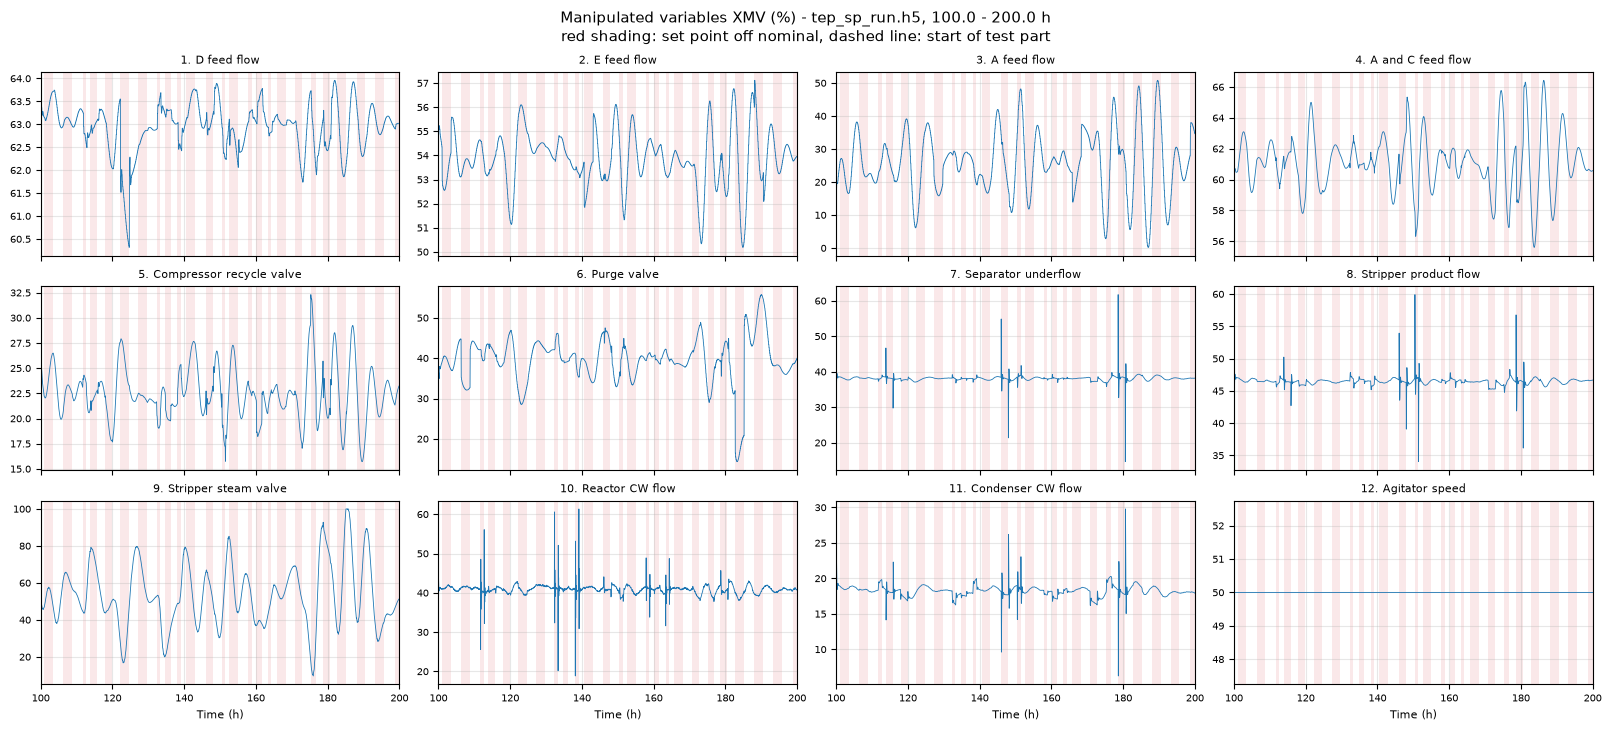

In [7]:
# Manipulated variables XMV (valve commands)
grid(data["xmv"], names["xmv"], "Manipulated variables XMV (%)", 4)

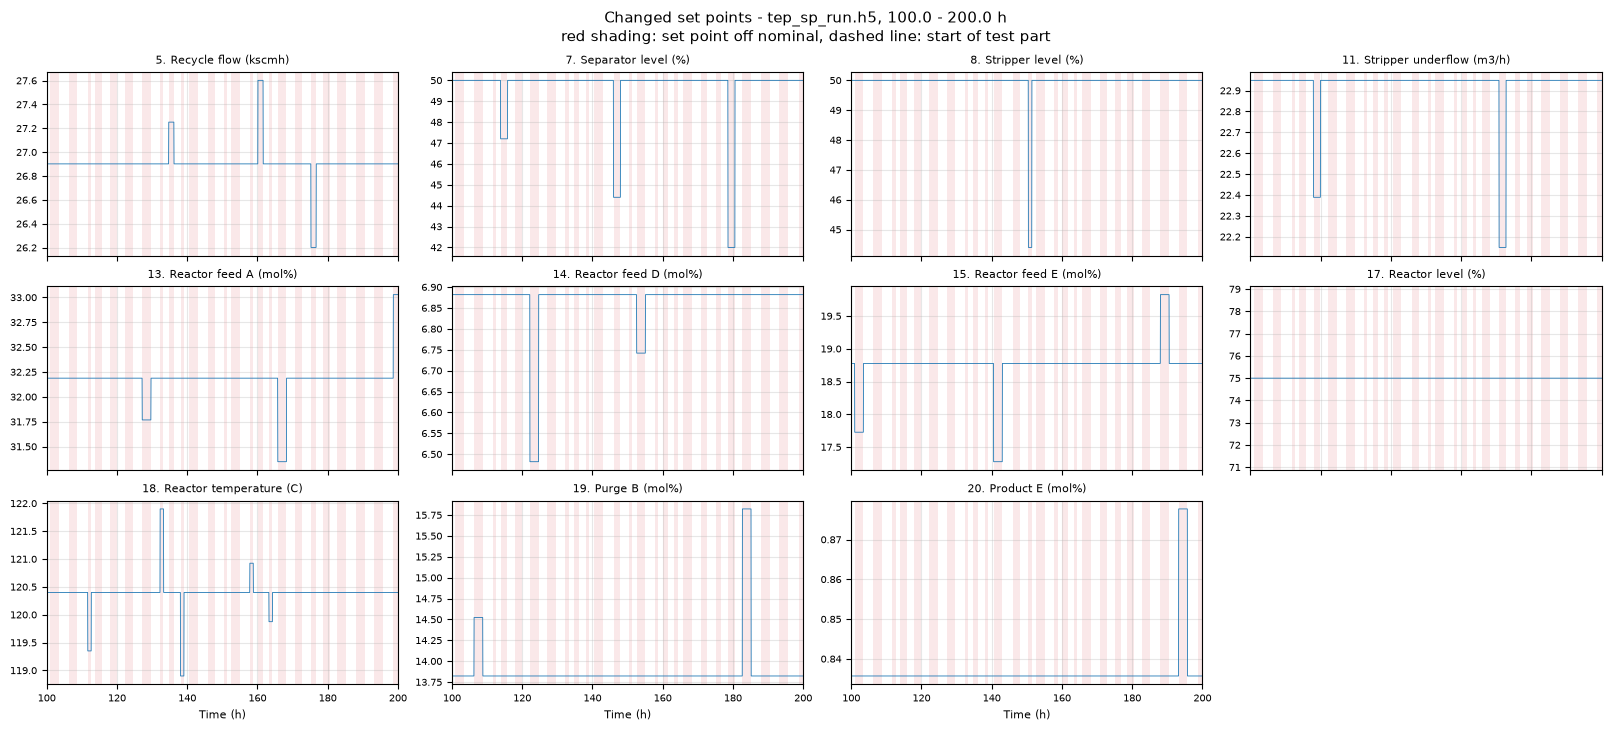

In [8]:
# Changed set points
grid(data["sp"], names["sp"], "Changed set points", 4, [k - 1 for k in changed])

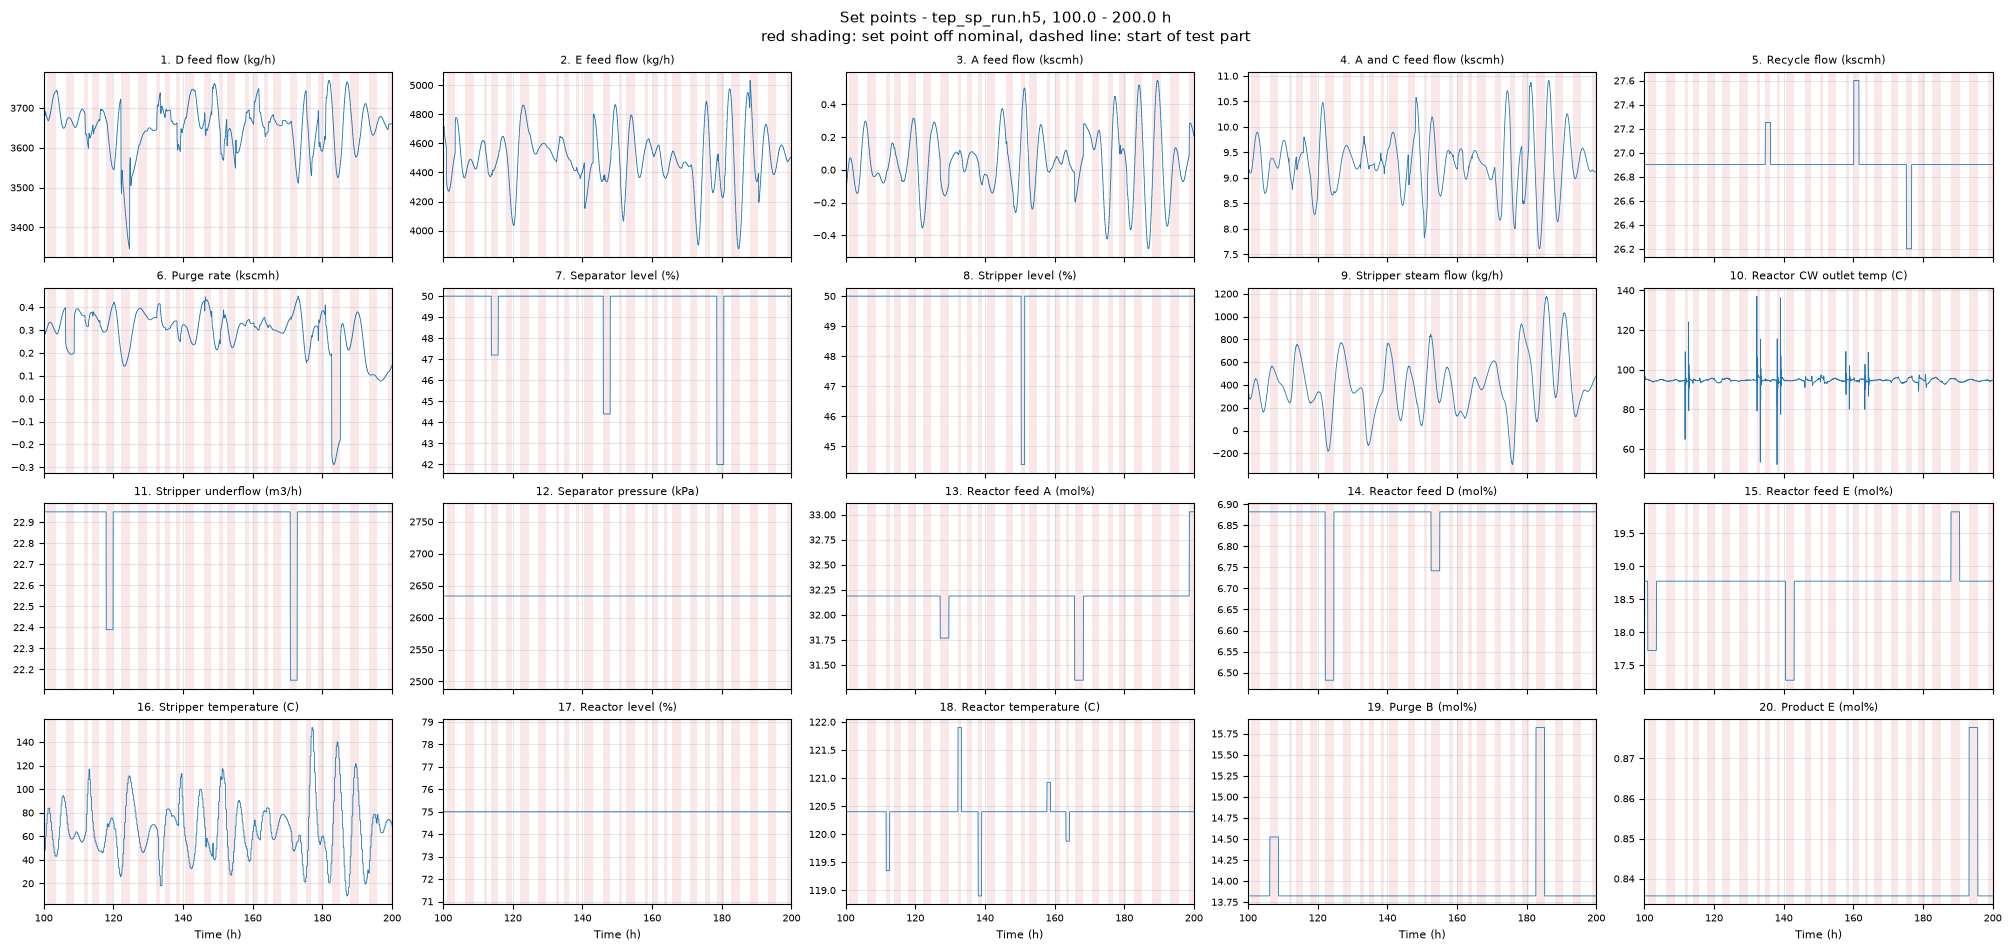

In [9]:
# All set points
grid(data["sp"], names["sp"], "Set points", 5)

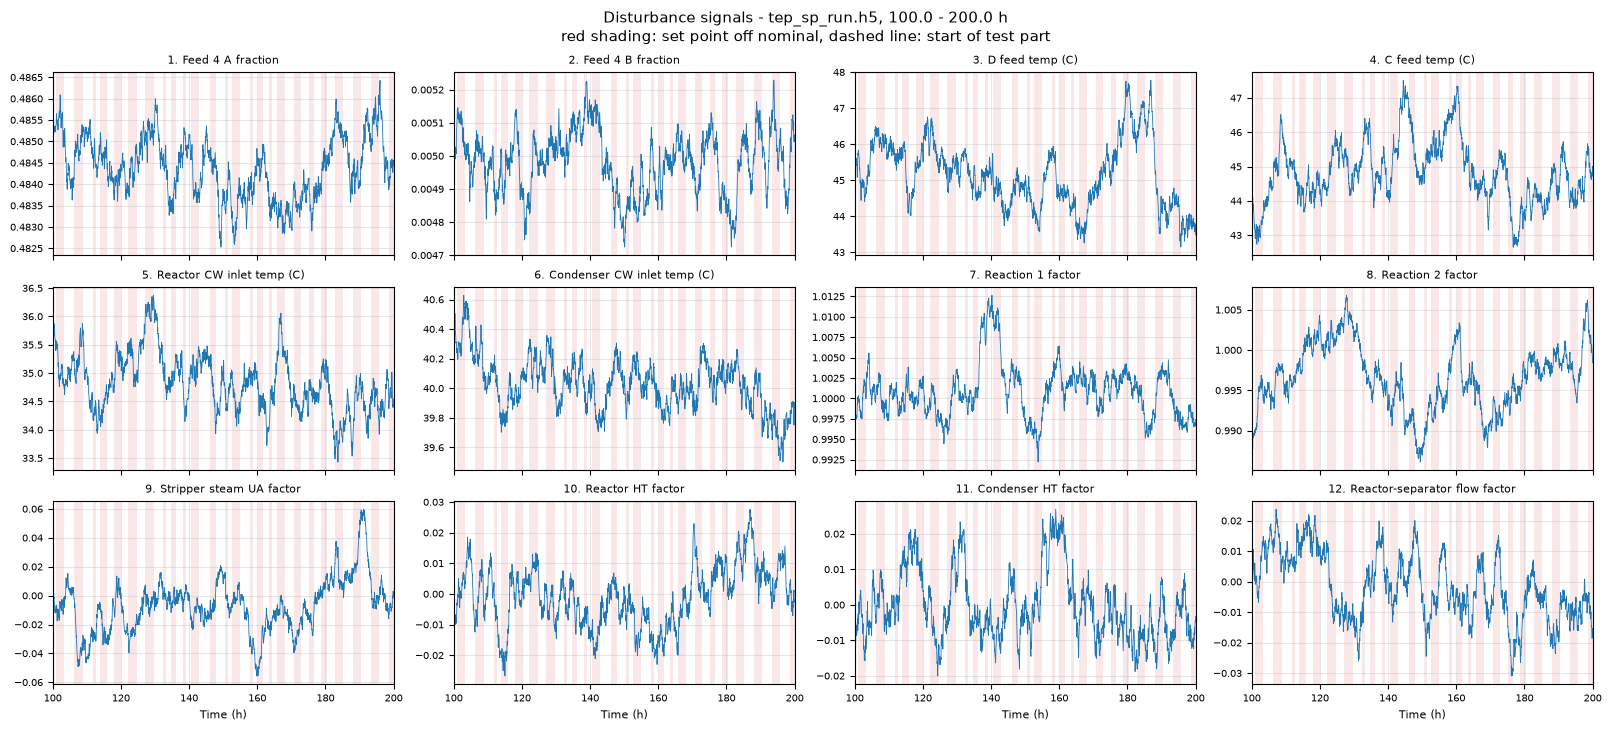

In [10]:
# Disturbance signals (AR(1))
grid(data["dist"], names["dist"], "Disturbance signals", 4)

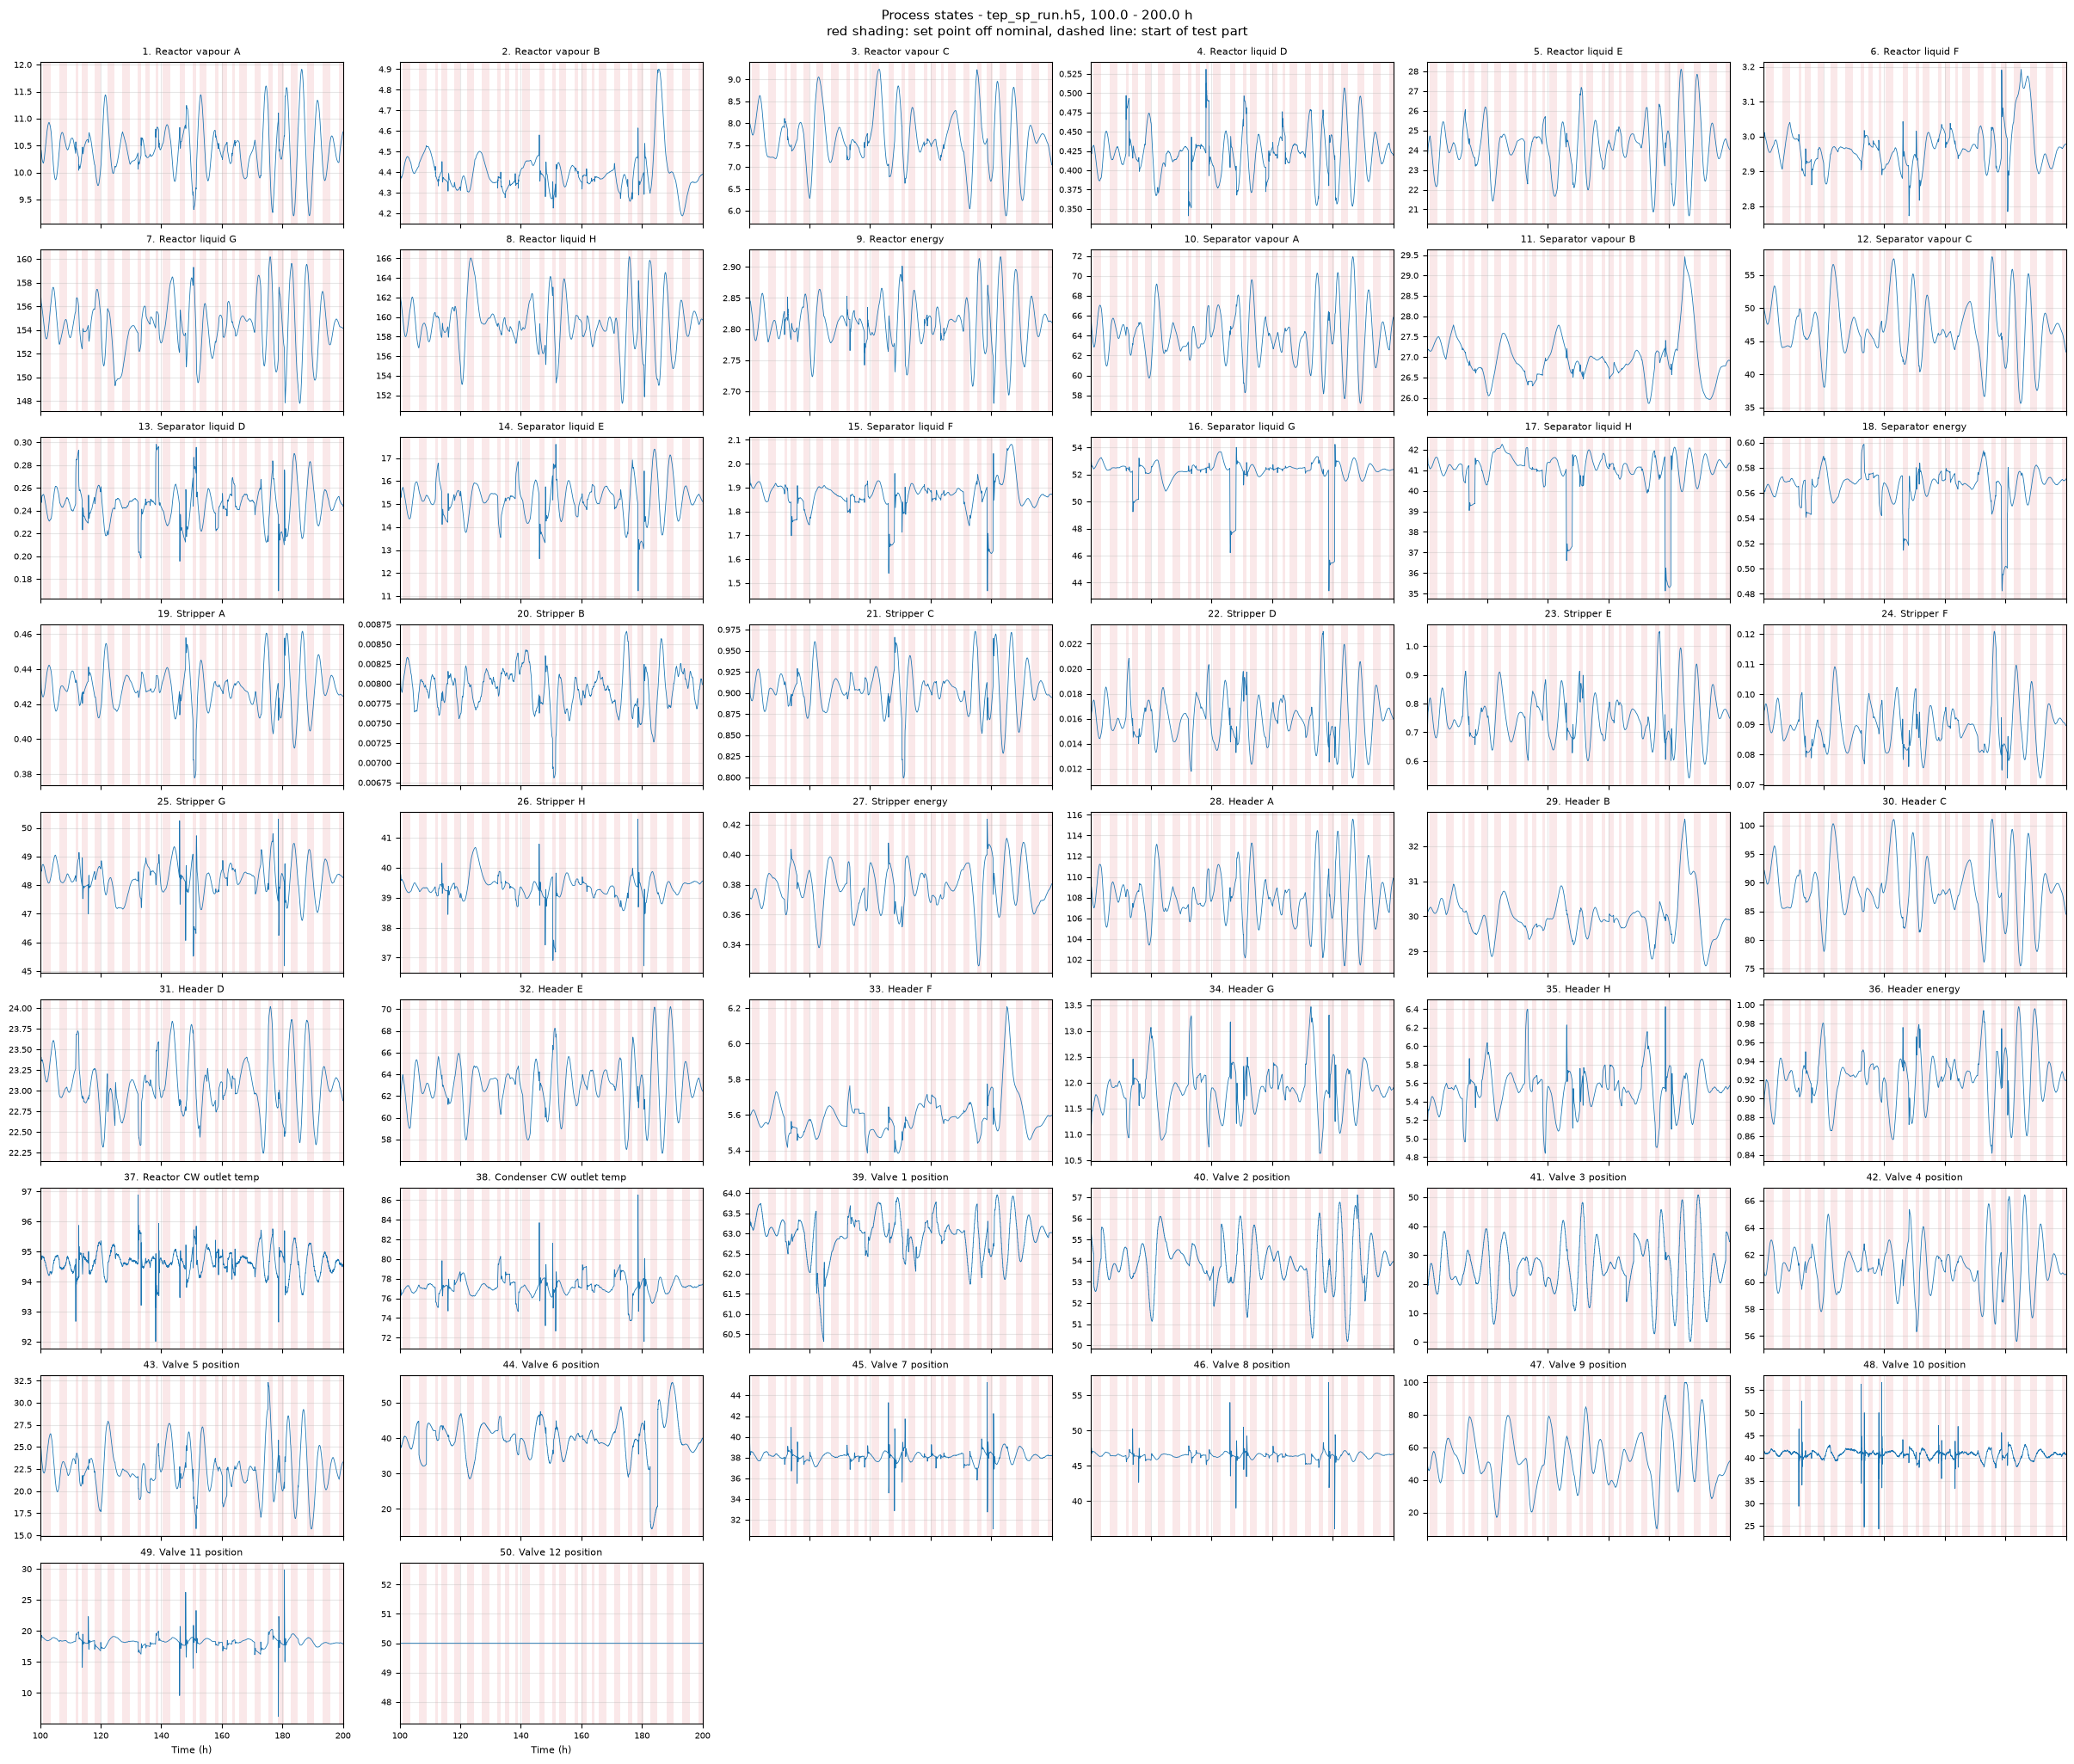

In [11]:
# Process states
if "y" in data:
    grid(data["y"], names["y"], "Process states", 6)